# 01 - Data export (Sentinel-1 monthly image + Dynamic World monthly label)

For every site in the `SITES` list below, this notebook downloads, for each month:
- **radar**: per-pixel median of that month's Sentinel-1 scenes (VV, VH in dB)
- **label**: Dynamic World class with the highest *month-averaged* probability
- **conf**: that highest averaged probability (how sure the label is)
- **n_scenes**: how many radar scenes went into the month
- **pass_dir**: which orbit direction was used (one per site, whichever has more scenes)

Each month is saved as `data/<site>_<year>-<month>.npz`. A pixel with no valid label is `255` (the ignore value).
Re-running skips months that are already saved, so an interrupted run just continues.

Before running: you need an Earth Engine account and a Google Cloud project registered for it.

## 1. Settings (edit these)

In [21]:
PROJECT = "deep-learning-project-512013"   # your Google Cloud project registered for Earth Engine
YEAR = 2024
MONTHS = range(1, 13)
SIZE_PX = 1000                # 1000 px x 10 m = 10 km square
SCALE = 10                    # metres per pixel (Sentinel-1 and Dynamic World are both 10 m)

# name, latitude, longitude, role. Proposed list, edit freely. Coordinates are approximate: check each on a map.
SITES = [
    ("kisumu",           -0.0917,  34.7680, "train"),
    ("morogoro",         -6.8210,  37.6615, "train"),
    ("ilorin",            8.4966,   4.5421, "train"),
    ("raipur",           21.2514,  81.6296, "train"),
    ("mymensingh",       24.7471,  90.4203, "train"),
    ("battambang",       13.0957, 103.2022, "train"),
    ("mzuzu",           -11.4656,  34.0207, "val"),
    ("warangal",         17.9689,  79.5941, "val"),
    ("bobo_dioulasso",   11.1771,  -4.2979, "test"),
    ("nashik",           19.9975,  73.7898, "test"),
    # rural sites found by the screening in section 9 (built share under 15%, fully labelled)
    ("kwara_rural",       8.0500,   4.1000, "train"),
    ("kilombero",        -8.3821,  36.4348, "train"),
    ("haor",             24.8171,  91.6486, "train"),
    ("chhattisgarh",     20.5326,  81.4656, "val"),
    ("e_zambia",        -13.6391,  32.3958, "val"),
    ("n_ghana",           9.6552,  -1.0924, "test"),
]

In [22]:
print(len(SITES))

16


## 2. Connect to Earth Engine

In [23]:
import os
import ee
import numpy as np
import matplotlib.pyplot as plt

try:
    ee.Initialize(project=PROJECT)
except Exception:
    # ask only for the Earth Engine permission, matching the single box ticked on the consent page
    ee.Authenticate(scopes=["https://www.googleapis.com/auth/earthengine"])
    ee.Initialize(project=PROJECT)

## 3. Helper functions

- `month_range` gives the start and end dates of one month.
- `pick_pass` chooses the orbit direction (ascending or descending) with more scenes at a site, so we never mix directions.
- `radar_month` builds the month's median radar image and counts the scenes.
- `label_month` averages Dynamic World's class probabilities over the month and picks the top class.
- `make_grid` builds the square pixel grid around a site.
- `download` pulls an Earth Engine image into a NumPy array for that grid.

In [24]:
import io

CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops",
           "shrub_and_scrub", "built", "bare", "snow_and_ice"]   # index in this list = label value
NODATA_LABEL = 255
NODATA_RADAR = -999.0


def month_range(year, month):
    """Start (inclusive) and end (exclusive) dates of one month."""
    start = ee.Date.fromYMD(year, month, 1)
    return start, start.advance(1, "month")


def pick_pass(region, year):
    """Orbit direction with the most Sentinel-1 scenes over the site in that year, or None if there are none.
    Some places are only covered from one direction, and mixing directions changes how things look."""
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(region)
          .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
          .filter(ee.Filter.eq("instrumentMode", "IW")))
    counts = s1.aggregate_histogram("orbitProperties_pass").getInfo()
    return max(counts, key=counts.get) if counts else None


def radar_month(region, start, end, pass_dir):
    """Median of all Sentinel-1 scenes in the month, per pixel, for VV and VH (dB).
    Also returns how many scenes were used. Scenes with missing data are skipped by the median."""
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
          .filterBounds(region).filterDate(start, end)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.eq("orbitProperties_pass", pass_dir))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    img = s1.select(["VV", "VH"]).median().unmask(NODATA_RADAR)
    return img, s1.size().getInfo()


def label_month(region, start, end):
    """Average each class's Dynamic World probability over the month, then take the best class.
    label = index of the best class, conf = its averaged probability.
    Pixels with no valid observation all month get label 255 and conf 0.
    If Dynamic World has no image at all that month (cloudy), the whole label is 255."""
    dw = (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
          .filterBounds(region).filterDate(start, end).select(CLASSES))
    if dw.size().getInfo() == 0:
        return ee.Image.constant([NODATA_LABEL, 0]).rename(["label", "conf"])
    probs = dw.mean()                                 # 9 bands: month-average probability per class
    label = probs.toArray().arrayArgmax().arrayGet(0).rename("label").unmask(NODATA_LABEL)
    conf = probs.reduce(ee.Reducer.max()).rename("conf").unmask(0)
    return label.addBands(conf)


def make_grid(lat, lon):
    """Pixel grid: SIZE_PX x SIZE_PX squares of SCALE metres, centred on the site, in the local UTM projection.
    Using metres (UTM) keeps pixels square."""
    zone = int((lon + 180) // 6) + 1
    epsg = f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"
    x, y = ee.Geometry.Point([lon, lat]).transform(epsg, 1).coordinates().getInfo()
    half = SIZE_PX * SCALE / 2
    grid = {"dimensions": {"width": SIZE_PX, "height": SIZE_PX},
            "affineTransform": {"scaleX": SCALE, "shearX": 0, "translateX": x - half,
                                "shearY": 0, "scaleY": -SCALE, "translateY": y + half},
            "crsCode": epsg}
    region = ee.Geometry.Rectangle([x - half, y - half, x + half, y + half], epsg, False)
    return grid, region


def download(image, grid):
    """Pull an Earth Engine image into an array shaped (bands, height, width).
    Earth Engine sends raw NPY bytes, so np.load decodes them into a table with one named field per band."""
    raw = ee.data.computePixels({"expression": image, "fileFormat": "NPY", "grid": grid})
    arr = np.load(io.BytesIO(raw))
    return np.stack([arr[name] for name in arr.dtype.names])

## 4. Download every site and month

Months already saved are skipped. A month that fails (for example a network timeout) prints the error and the loop moves on, so just run the cell again to fill any gaps.

In [26]:
import csv

os.makedirs("data", exist_ok=True)
with open("data/sites.csv", "w", newline="") as fh:        # which site plays which role (train / val / test)
    csv.writer(fh).writerows([("name", "lat", "lon", "role"), *SITES])

for name, lat, lon, role in SITES:
    grid, region = make_grid(lat, lon)
    pass_dir = pick_pass(region, YEAR)
    if pass_dir is None:
        print(f"{name}: no Sentinel-1 scenes, skipped")
        continue
    print(f"{name} ({role}): using {pass_dir} passes")
    for m in MONTHS:
        out = f"data/{name}_{YEAR}-{m:02d}.npz"
        if os.path.exists(out):
            continue
        try:
            start, end = month_range(YEAR, m)
            radar_img, n_scenes = radar_month(region, start, end, pass_dir)
            if n_scenes == 0:
                print(f"  {YEAR}-{m:02d}: no radar scenes, skipped")
                continue
            radar = download(radar_img, grid).astype("float32")      # (2, H, W)
            lab = download(label_month(region, start, end), grid)    # (2, H, W): label, conf
            tmp = out + ".part"                                      # write then rename, so a stopped run never leaves a broken file
            with open(tmp, "wb") as fh:
                np.savez_compressed(fh, radar=radar, label=lab[0].astype("uint8"),
                                    conf=lab[1].astype("float32"), n_scenes=n_scenes, pass_dir=pass_dir)
            os.replace(tmp, out)
            print(f"  {YEAR}-{m:02d}: {n_scenes} scenes saved")
        except Exception as e:
            print(f"  {YEAR}-{m:02d}: FAILED ({type(e).__name__}: {e}); run the cell again to retry")

kisumu (train): using ASCENDING passes
morogoro (train): using ASCENDING passes
ilorin (train): using ASCENDING passes
raipur (train): using DESCENDING passes
mymensingh (train): using ASCENDING passes
battambang (train): using DESCENDING passes
mzuzu (val): using DESCENDING passes
warangal (val): using DESCENDING passes
bobo_dioulasso (test): using ASCENDING passes
nashik (test): using DESCENDING passes
kwara_rural (train): using ASCENDING passes
  2024-01: 4 scenes saved
  2024-02: 3 scenes saved
  2024-03: 4 scenes saved
  2024-04: 5 scenes saved
  2024-05: 4 scenes saved
  2024-06: 5 scenes saved
  2024-07: 4 scenes saved
  2024-08: 5 scenes saved
  2024-09: 6 scenes saved
  2024-10: 5 scenes saved
  2024-11: 5 scenes saved
  2024-12: 5 scenes saved
kilombero (train): using ASCENDING passes
  2024-01: 5 scenes saved
  2024-02: 5 scenes saved
  2024-03: 5 scenes saved
  2024-04: 5 scenes saved
  2024-05: 5 scenes saved
  2024-06: 4 scenes saved
  2024-07: 5 scenes saved
  2024-08: 5

## 5. Sanity check (fails loudly if something is off)

In [27]:
import glob
import collections

per_site = collections.defaultdict(list)
for f in sorted(glob.glob("data/*.npz")):
    d = np.load(f)
    assert d["radar"].shape == (2, SIZE_PX, SIZE_PX), f
    assert d["label"].shape == (SIZE_PX, SIZE_PX), f
    assert set(np.unique(d["label"])) <= set(range(len(CLASSES))) | {NODATA_LABEL}, f
    site = os.path.basename(f).rsplit("_", 1)[0]
    per_site[site].append((int(d["n_scenes"]), float((d["label"] == NODATA_LABEL).mean())))

for site, rows in per_site.items():
    scenes = [r[0] for r in rows]
    print(f"{site}: {len(rows)}/12 months, scenes per month {min(scenes)}-{max(scenes)}, "
          f"worst no-label share {max(r[1] for r in rows):.3f}")
missing = [n for n, *_ in SITES if n not in per_site]
print("sites with no data:", missing or "none")

battambang: 12/12 months, scenes per month 4-6, worst no-label share 1.000
bobo_dioulasso: 12/12 months, scenes per month 2-3, worst no-label share 1.000
chhattisgarh: 12/12 months, scenes per month 2-6, worst no-label share 1.000
e_zambia: 12/12 months, scenes per month 2-5, worst no-label share 0.582
haor: 12/12 months, scenes per month 2-3, worst no-label share 1.000
ilorin: 12/12 months, scenes per month 1-3, worst no-label share 1.000
kilombero: 12/12 months, scenes per month 4-5, worst no-label share 1.000
kisumu: 12/12 months, scenes per month 2-3, worst no-label share 0.041
kwara_rural: 12/12 months, scenes per month 3-6, worst no-label share 1.000
morogoro: 12/12 months, scenes per month 3-6, worst no-label share 1.000
mymensingh: 12/12 months, scenes per month 1-3, worst no-label share 1.000
mzuzu: 12/12 months, scenes per month 2-6, worst no-label share 1.000
n_ghana: 12/12 months, scenes per month 2-3, worst no-label share 1.000
nashik: 12/12 months, scenes per month 2-6, w

## 6. Look at one month

Change `SHOW` to any site name from the list to inspect it.

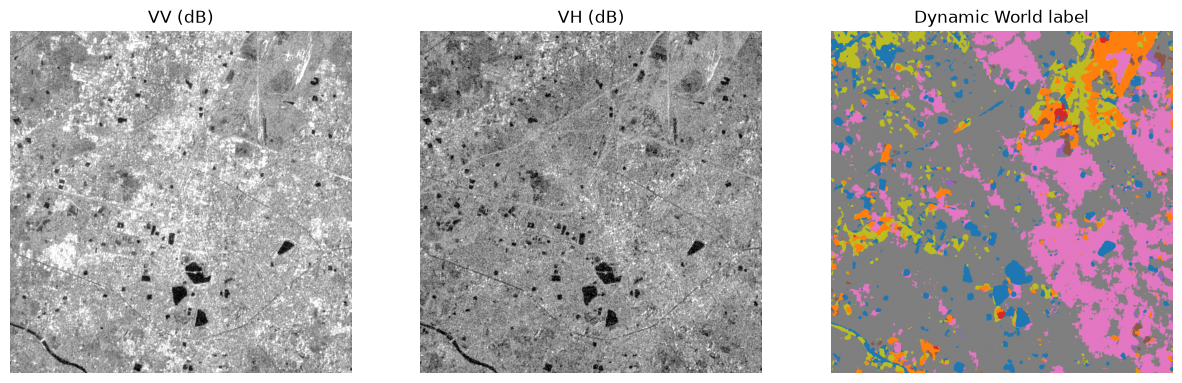

classes: {0: 'water', 1: 'trees', 2: 'grass', 3: 'flooded_vegetation', 4: 'crops', 5: 'shrub_and_scrub', 6: 'built', 7: 'bare', 8: 'snow_and_ice'}


In [9]:
SHOW = "raipur"
f = sorted(glob.glob(f"data/{SHOW}_{YEAR}-*.npz"))[0]
d = np.load(f)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(d["radar"][0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("VV (dB)")
ax[1].imshow(d["radar"][1], cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("VH (dB)")
im = ax[2].imshow(np.where(d["label"] == NODATA_LABEL, np.nan, d["label"]), cmap="tab10", vmin=0, vmax=9)
ax[2].set_title("Dynamic World label")
for a in ax: a.axis("off")
plt.show()
print("classes:", dict(enumerate(CLASSES)))

## 7. Bundle the dataset

One zip to upload to Drive and share, for the server and for the submission.

In [28]:
import shutil

shutil.make_archive("dataset", "zip", "data")   # makes dataset.zip next to this notebook; upload it to Drive and share the link
print("dataset.zip size (MB):", round(os.path.getsize("dataset.zip") / 1e6))

dataset.zip size (MB): 1839


## 8. Yearly labels (baseline label per site)

One label per site for the whole year, with its confidence. It is the same calculation as the monthly label, just over 12 months, so `label_month` is reused. Saved to `data/yearly/<site>_<year>.npz`. The rule for combining monthly and yearly labels belongs to the training step, not here.

In [31]:
os.makedirs("data/yearly", exist_ok=True)
year_start, year_end = ee.Date.fromYMD(YEAR, 1, 1), ee.Date.fromYMD(YEAR + 1, 1, 1)

for name, lat, lon, role in SITES:
    out = f"data/yearly/{name}_{YEAR}.npz"
    if os.path.exists(out):
        continue
    try:
        grid, region = make_grid(lat, lon)
        lab = download(label_month(region, year_start, year_end), grid)    # (2, H, W): label, conf
        tmp = out + ".part"
        with open(tmp, "wb") as fh:
            np.savez_compressed(fh, label=lab[0].astype("uint8"), conf=lab[1].astype("float32"))
        os.replace(tmp, out)
        print(f"{name}: saved, share of pixels with no label {float((lab[0] == NODATA_LABEL).mean()):.3f}")
    except Exception as e:
        print(f"{name}: FAILED ({type(e).__name__}: {e}); run the cell again to retry")

### Check the yearly labels

Shapes must match the monthly arrays, and every label must be a valid class or 255. Also prints each site's class shares, which is useful for the report's class-distribution section.

In [32]:
for f in sorted(glob.glob(f"data/yearly/*_{YEAR}.npz")):
    d = np.load(f)
    assert d["label"].shape == (SIZE_PX, SIZE_PX) and d["conf"].shape == (SIZE_PX, SIZE_PX), f
    assert set(np.unique(d["label"])) <= set(range(len(CLASSES))) | {NODATA_LABEL}, f
    shares = np.bincount(d["label"].ravel(), minlength=256) / d["label"].size
    top = {CLASSES[i]: round(float(shares[i]), 2) for i in range(len(CLASSES)) if shares[i] >= 0.01}
    print(os.path.basename(f), "| mean conf %.2f" % d["conf"].mean(), "| no label %.3f" % shares[NODATA_LABEL], "|", top)
print("sites with a yearly label:", len(glob.glob(f"data/yearly/*_{YEAR}.npz")), "of", len(SITES))

battambang_2024.npz | mean conf 0.49 | no label 0.000 | {'water': 0.02, 'trees': 0.07, 'crops': 0.33, 'shrub_and_scrub': 0.02, 'built': 0.55}
bobo_dioulasso_2024.npz | mean conf 0.47 | no label 0.000 | {'trees': 0.11, 'crops': 0.01, 'shrub_and_scrub': 0.21, 'built': 0.62, 'bare': 0.04}
chhattisgarh_2024.npz | mean conf 0.42 | no label 0.000 | {'water': 0.18, 'trees': 0.44, 'crops': 0.2, 'shrub_and_scrub': 0.16, 'built': 0.02}
e_zambia_2024.npz | mean conf 0.37 | no label 0.000 | {'trees': 0.26, 'crops': 0.23, 'shrub_and_scrub': 0.48, 'built': 0.03}
haor_2024.npz | mean conf 0.31 | no label 0.000 | {'water': 0.11, 'trees': 0.21, 'grass': 0.02, 'flooded_vegetation': 0.27, 'crops': 0.33, 'built': 0.06}
ilorin_2024.npz | mean conf 0.54 | no label 0.000 | {'trees': 0.01, 'crops': 0.02, 'shrub_and_scrub': 0.03, 'built': 0.93}
kilombero_2024.npz | mean conf 0.29 | no label 0.000 | {'water': 0.13, 'trees': 0.06, 'grass': 0.12, 'flooded_vegetation': 0.45, 'crops': 0.02, 'shrub_and_scrub': 0.21}

In [33]:
import shutil

shutil.make_archive("yearly", "zip", "data/yearly")   # tiny; upload next to dataset.zip
print("yearly.zip size (MB):", round(os.path.getsize("yearly.zip") / 1e6, 1))

yearly.zip size (MB): 56.0


## 9. Find rural sites automatically

Instead of checking places on a map by hand, search around a few rough starting points. Each base point is tried on a 3x3 grid about 28 km apart. For every candidate square, Earth Engine reports what the yearly Dynamic World label is made of (computed at a coarse 100 m scale, so nothing big is downloaded).

A candidate passes if it is not mostly built up and is well labelled. For each base point the most varied passing square (highest class diversity) wins. The winners print as lines ready to paste into `SITES`. Then glance at each winner on a satellite map, which takes minutes instead of an hour.

The screening label is Dynamic World itself, so a badly labelled square could slip through. That is what the quick look at the winners is for.

In [15]:
import itertools
import math

# rough starting points (name, lat, lon, role); coordinates are approximate on purpose, the search moves around them
BASES = [   # anchors are town centres from OpenStreetMap's Nominatim (kwara_rural is still a rough guess); the grid search finds the countryside around them
    ("kwara_rural",    8.3000,   4.1000, "train"),
    ("kilombero",     -8.1321,  36.6848, "train"),   # Ifakara
    ("haor",          25.0671,  91.3986, "train"),   # Sunamganj
    ("chhattisgarh",  20.5326,  81.7156, "val"),     # Dhamtari
    ("e_zambia",     -13.6391,  32.6458, "val"),     # Chipata
    ("n_ghana",        9.4052,  -0.8424, "test"),    # Tamale
]
STEP = 0.25            # degrees between candidates, about 28 km
MAX_BUILT = 0.15       # a site passes only if less than this share is built up
MIN_LABELLED = 0.90    # ...and at least this share of the square has a label
year_start, year_end = ee.Date.fromYMD(YEAR, 1, 1), ee.Date.fromYMD(YEAR + 1, 1, 1)


def screen(lat, lon):
    """Class shares of the yearly label over the site's square, and the share of the square that has a label.
    Computed inside Earth Engine at 100 m, so there is nothing big to download."""
    _, region = make_grid(lat, lon)
    img = label_month(region, year_start, year_end).select("label")
    hist = img.reduceRegion(ee.Reducer.frequencyHistogram(), region, 100, maxPixels=1e9).get("label").getInfo()
    total = sum(hist.values())
    shares = {int(float(k)): v / total for k, v in hist.items()}
    assert abs(sum(shares.values()) - 1) < 1e-6
    return shares, 1 - shares.get(NODATA_LABEL, 0)


candidates = []
for base, lat0, lon0, role in BASES:
    for dy, dx in itertools.product((-1, 0, 1), repeat=2):
        lat, lon = lat0 + dy * STEP, lon0 + dx * STEP
        try:
            shares, labelled = screen(lat, lon)
        except Exception as e:
            print(f"{base} ({lat:.2f}, {lon:.2f}): FAILED ({type(e).__name__}); skipped")
            continue
        classes = {k: v for k, v in shares.items() if k != NODATA_LABEL}
        built = classes.get(CLASSES.index("built"), 0)
        diversity = -sum(p * math.log(p) for p in classes.values() if p > 0)   # higher = more evenly mixed classes
        candidates.append(dict(base=base, role=role, lat=round(lat, 4), lon=round(lon, 4),
                               built=built, labelled=labelled, diversity=diversity, classes=classes))
    print(f"{base}: {sum(c['base'] == base for c in candidates)} candidates screened")

kwara_rural: 9 candidates screened
kilombero: 9 candidates screened
haor: 9 candidates screened
chhattisgarh: 9 candidates screened
e_zambia: 9 candidates screened
n_ghana: 9 candidates screened


In [16]:
winners = []
for base, lat0, lon0, role in BASES:
    ok = [c for c in candidates if c["base"] == base and c["built"] <= MAX_BUILT and c["labelled"] >= MIN_LABELLED]
    if not ok:
        best = min((c for c in candidates if c["base"] == base), key=lambda c: c["built"], default=None)
        print(f"{base}: NO candidate passed. Lowest built share was",
              f"{best['built']:.2f} at ({best['lat']}, {best['lon']})" if best else "n/a (all failed)")
        continue
    best = max(ok, key=lambda c: c["diversity"])
    winners.append(best)
    top = {CLASSES[k]: round(v, 2) for k, v in sorted(best["classes"].items(), key=lambda kv: -kv[1]) if v >= 0.02}
    print(f"{base}: {len(ok)}/9 passed; winner ({best['lat']}, {best['lon']}) built {best['built']:.2f} labelled {best['labelled']:.2f} {top}")

print("\n# paste into SITES after a quick look at each on a satellite map:")
for w in winners:
    print(f'    ("{w["base"]}", {w["lat"]:>8}, {w["lon"]:>8}, "{w["role"]}"),')

kwara_rural: 9/9 passed; winner (8.05, 4.1) built 0.03 labelled 1.00 {'trees': 0.49, 'shrub_and_scrub': 0.33, 'crops': 0.15, 'built': 0.03}
kilombero: 8/9 passed; winner (-8.3821, 36.4348) built 0.00 labelled 1.00 {'flooded_vegetation': 0.47, 'shrub_and_scrub': 0.21, 'water': 0.13, 'grass': 0.12, 'trees': 0.06}
haor: 9/9 passed; winner (24.8171, 91.6486) built 0.05 labelled 1.00 {'crops': 0.34, 'flooded_vegetation': 0.27, 'trees': 0.22, 'water': 0.1, 'built': 0.05}
chhattisgarh: 8/9 passed; winner (20.5326, 81.4656) built 0.01 labelled 1.00 {'trees': 0.44, 'crops': 0.2, 'water': 0.18, 'shrub_and_scrub': 0.16}
e_zambia: 8/9 passed; winner (-13.6391, 32.3958) built 0.03 labelled 1.00 {'shrub_and_scrub': 0.5, 'trees': 0.25, 'crops': 0.22, 'built': 0.03}
n_ghana: 8/9 passed; winner (9.6552, -1.0924) built 0.00 labelled 1.00 {'shrub_and_scrub': 0.65, 'crops': 0.19, 'trees': 0.11, 'water': 0.03, 'bare': 0.02}

# paste into SITES after a quick look at each on a satellite map:
    ("kwara_rura